# Visualizing embeddings in 3D

The example uses [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) to reduce the dimensionality fo the embeddings from 1536 to 3. Then we can visualize the data points in a 3D plot. The small dataset `dbpedia_samples.jsonl` is curated by randomly sampling 200 samples from [DBpedia validation dataset](https://www.kaggle.com/danofer/dbpedia-classes?select=DBPEDIA_val.csv).

### 1. Load the dataset and query embeddings

In [1]:
import pandas as pd

# JSONL 파일을 데이터프레임으로 로드
# lines=True: 각 줄이 독립적인 JSON 객체인 JSONL 형식 파싱
samples = pd.read_json("data/dbpedia_samples.jsonl", lines=True)

# category 컬럼의 고유값을 추출 후 알파벳 순으로 정렬
categories = sorted(samples["category"].unique())

# 카테고리별 샘플 수 출력
print("Categories of DBpedia samples:", samples["category"].value_counts())

# 데이터프레임 상위 5행 미리보기
samples.head()


Categories of DBpedia samples: category
Artist                    21
Film                      19
Plant                     19
OfficeHolder              18
Company                   17
NaturalPlace              16
Athlete                   16
Village                   12
Building                  11
WrittenWork               11
Album                     11
Animal                    11
EducationalInstitution    10
MeanOfTransportation       8
Name: count, dtype: int64


,text,category
0,Morada Limited is a textile company based in ...,Company
1,The Armenian Mirror-Spectator is a newspaper ...,WrittenWork
2,Mt. Kinka (金華山 Kinka-zan) also known as Kinka...,NaturalPlace
3,Planning the Play of a Bridge Hand is a book ...,WrittenWork
4,Wang Yuanping (born 8 December 1976) is a ret...,Athlete


In [6]:
from embeddings_utils import get_embeddings

# 주의: 아래 코드는 200개 배치 크기로 /embeddings 엔드포인트에 요청을 전송합니다
# samples 데이터프레임의 text 컬럼을 리스트로 변환 후 일괄 임베딩 요청
matrix = get_embeddings(samples["text"].to_list(), model="text-embedding-3-small")


### 2. Reduce the embedding dimensionality

In [7]:
from sklearn.decomposition import PCA

# PCA 모델 생성 : 고차원 임베딩을 3차원으로 축소
pca = PCA(n_components=3)

# 임베딩 행렬에 PCA 적용 → 3D 좌표 배열 반환
# matrix shape: (200, 1536) → vis_dims shape: (200, 3)
vis_dims = pca.fit_transform(matrix)

# 3D 좌표를 리스트 형태로 변환 후 데이터프레임 새 컬럼에 저장
samples["embed_vis"] = vis_dims.tolist()

### 3. Plot the embeddings of lower dimensionality

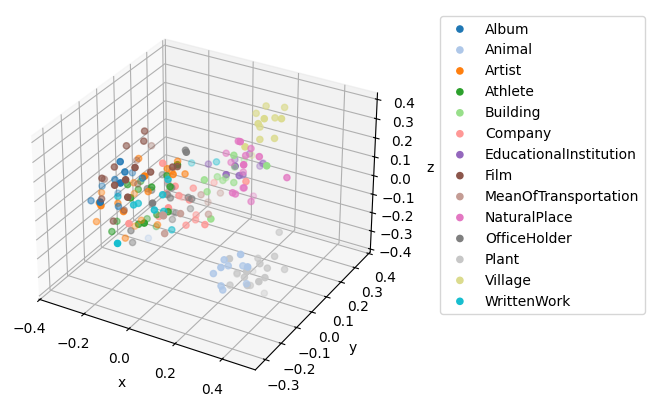

In [8]:
import matplotlib.pyplot as plt
import numpy as np

# 10x5 크기의 3D 플롯 figure 생성
fig = plt.figure(figsize=(10, 5))

# 3D 축 추가
ax = fig.add_subplot(projection='3d')

# 20가지 색상을 제공하는 컬러맵 설정
cmap = plt.get_cmap("tab20")

# 카테고리별로 개별 산점도 생성 (범례 이름 지정을 위해 분리)
for i, cat in enumerate(categories):
    # 해당 카테고리의 3D 좌표 데이터만 추출 후 numpy 배열로 변환
    sub_matrix = np.array(samples[samples["category"] == cat]["embed_vis"].to_list())
    
    # 3D 좌표 분리
    x = sub_matrix[:, 0]  # 1번째 PCA 성분
    y = sub_matrix[:, 1]  # 2번째 PCA 성분
    z = sub_matrix[:, 2]  # 3번째 PCA 성분
    
    # 카테고리별 고유 색상 지정 (전체 카테고리 수로 나눠 균등 배분)
    colors = [cmap(i/len(categories))] * len(sub_matrix)
    
    # 3D 산점도에 해당 카테고리 데이터 추가
    ax.scatter(x, y, zs=z, zdir='z', c=colors, label=cat)

# 축 레이블 설정
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')

# 범례를 차트 오른쪽 상단 바깥에 배치
ax.legend(bbox_to_anchor=(1.1, 1))
